# Module 6 — TwoLayerNet with Numerical Gradients

**Objective:** implement a two-layer neural network (`TwoLayerNet`) whose parameters are
trained with **numerical gradients** (central differences), and apply it to the
**Iris** and **MNIST** datasets.

Project layout:

```
module6/
├── module6.ipynb          ← this notebook
├── two_layer_net.py       ← TwoLayerNet class (numerical gradient)
├── datasets.py            ← Iris / MNIST loaders
├── dataset/
│   ├── iris.csv
│   ├── train-images-idx3-ubyte.gz, train-labels-idx1-ubyte.gz
│   └── t10k-images-idx3-ubyte.gz,  t10k-labels-idx1-ubyte.gz
├── almahaini_iris_nn_model.pkl   ← produced by Part 1
└── almahaini_mnist_nn_model.pkl  ← produced by Part 2
```


In [1]:
import pickle
import time
import numpy as np
import matplotlib.pyplot as plt

from two_layer_net import TwoLayerNet
from datasets import load_iris_data, load_mnist, IRIS_CLASSES

LAST_NAME = "almahaini"
np.random.seed(0)

## The `TwoLayerNet` class

The implementation lives in `two_layer_net.py` and is shown below for reference.
Forward pass: `Affine → sigmoid → Affine → softmax`; loss: cross-entropy;
gradients: `numerical_gradient()` evaluates the loss at `θ ± h` (h = 1e-4) for **every**
parameter — slow but requires no back-propagation.

In [2]:
from IPython.display import Code
Code(filename="two_layer_net.py", language="python")

"""
two_layer_net.py
----------------
A two-layer (one hidden layer) fully-connected neural network whose
gradients are computed with *numerical differentiation* (central
differences), following "Deep Learning from Scratch", Chapter 4.

Architecture:  input -> Affine -> sigmoid -> Affine -> softmax
Loss:          cross-entropy error on one-hot (or integer) labels
"""

import numpy as np


# ---------------------------------------------------------------------------
# Activation / loss helpers
# ---------------------------------------------------------------------------
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def softmax(x):
    # subtract the row-wise max for numerical stability
    x = x - np.max(x, axis=-1, keepdims=True)
    e = np.exp(x)
    return e / np.sum(e, axis=-1, keepdims=True)


def cross_entropy_error(y, t):
    """y: network output (N, C) ; t: one-hot (N, C) or integer labels (N,)"""
    if y.ndim == 1:
        y = y.reshape(1, -1)
        t = t.reshape(1, -1)

    # if labels are one-hot, convert to class indices
    if t.size == y.size:
        t = t.argmax(axis=1)

    batch_size = y.shape[0]
    return -np.sum(np.log(y[np.arange(batch_size), t] + 1e-7)) / batch_size


def numerical_gradient(f, x):
    """Central-difference numerical gradient of scalar function f at array x."""
    h = 1e-4
    grad = np.zeros_like(x)

    it = np.nditer(x, flags=["multi_index"], op_flags=["readwrite"])
    while not it.finished:
        idx = it.multi_index
        tmp = x[idx]

        x[idx] = tmp + h
        fxh1 = f(x)          # f(x + h)

        x[idx] = tmp - h
        fxh2 = f(x)          # f(x - h)

        grad[idx] = (fxh1 - fxh2) / (2 * h)
        x[idx] = tmp         # restore
        it.iternext()

    return grad


# ---------------------------------------------------------------------------
# The network
# ---------------------------------------------------------------------------
class TwoLayerNet:
    def __init__(self, input_size, hidden_size, output_size, weight_init_std=0.01):
        self.params = {}
        self.params["W1"] = weight_init_std * np.random.randn(input_size, hidden_size)
        self.params["b1"] = np.zeros(hidden_size)
        self.params["W2"] = weight_init_std * np.random.randn(hidden_size, output_size)
        self.params["b2"] = np.zeros(output_size)

    # forward pass ---------------------------------------------------------
    def predict(self, x):
        W1, W2 = self.params["W1"], self.params["W2"]
        b1, b2 = self.params["b1"], self.params["b2"]

        a1 = np.dot(x, W1) + b1
        z1 = sigmoid(a1)
        a2 = np.dot(z1, W2) + b2
        y = softmax(a2)
        return y

    # loss -----------------------------------------------------------------
    def loss(self, x, t):
        y = self.predict(x)
        return cross_entropy_error(y, t)

    # accuracy -------------------------------------------------------------
    def accuracy(self, x, t):
        y = np.argmax(self.predict(x), axis=1)
        if t.ndim != 1:
            t = np.argmax(t, axis=1)
        return np.sum(y == t) / float(x.shape[0])

    # numerical gradient ---------------------------------------------------
    def numerical_gradient(self, x, t):
        loss_W = lambda W: self.loss(x, t)

        grads = {}
        for key in ("W1", "b1", "W2", "b2"):
            grads[key] = numerical_gradient(loss_W, self.params[key])
        return grads

    # one SGD step ---------------------------------------------------------
    def update(self, x, t, learning_rate):
        grads = self.numerical_gradient(x, t)
        for key in self.params:
            self.params[key] -= learning_rate * grads[key]

## Helper: generic training loop

In [3]:
def train(net, x_train, t_train, x_test, t_test, *, iters, batch_size, lr, log_every):
    """Mini-batch SGD using TwoLayerNet.numerical_gradient. Returns history dict."""
    n = x_train.shape[0]
    hist = {"iter": [], "loss": [], "train_acc": [], "test_acc": []}
    t0 = time.time()
    for i in range(1, iters + 1):
        idx = np.random.choice(n, batch_size, replace=False)
        net.update(x_train[idx], t_train[idx], lr)

        if i % log_every == 0 or i == 1 or i == iters:
            loss = net.loss(x_train[idx], t_train[idx])
            tr_acc, te_acc = net.accuracy(x_train, t_train), net.accuracy(x_test, t_test)
            hist["iter"].append(i); hist["loss"].append(loss)
            hist["train_acc"].append(tr_acc); hist["test_acc"].append(te_acc)
            print(f"iter {i:5d} | loss {loss:.4f} | train acc {tr_acc:.4f} | "
                  f"test acc {te_acc:.4f} | {time.time() - t0:6.1f}s")
    return hist


def plot_history(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(hist["iter"], hist["loss"]); ax[0].set_title("mini-batch loss")
    ax[0].set_xlabel("iteration"); ax[0].set_ylabel("cross-entropy")
    ax[1].plot(hist["iter"], hist["train_acc"], label="train")
    ax[1].plot(hist["iter"], hist["test_acc"], label="test")
    ax[1].set_title("accuracy"); ax[1].set_xlabel("iteration"); ax[1].legend()
    fig.suptitle(title); plt.tight_layout(); plt.show()


def save_model(net, path):
    with open(path, "wb") as f:
        pickle.dump(net, f)
    print("saved ->", path)


def load_model(path):
    with open(path, "rb") as f:
        return pickle.load(f)

# Part 1 — Iris

150 samples, 4 features, 3 classes. `dataset/iris.csv` is split 80 / 20 (stratified,
120 train / 30 test) and features are standardised with the training mean / std.

## 1.1 Train

train: (120, 4) (120, 3)  test: (30, 4) (30, 3)
iter     1 | loss 1.0736 | train acc 0.3333 | test acc 0.3333 |    0.0s


iter   100 | loss 0.2954 | train acc 0.9250 | test acc 0.9333 |    0.3s


iter   200 | loss 0.2017 | train acc 0.9917 | test acc 0.9000 |    0.6s


iter   300 | loss 0.0745 | train acc 0.9833 | test acc 0.9000 |    0.9s


iter   400 | loss 0.0495 | train acc 0.9917 | test acc 0.9000 |    1.1s


iter   500 | loss 0.0638 | train acc 0.9833 | test acc 0.9333 |    1.5s


iter   600 | loss 0.0396 | train acc 0.9917 | test acc 0.9000 |    1.8s


iter   700 | loss 0.0250 | train acc 0.9917 | test acc 0.9000 |    2.2s


iter   800 | loss 0.0381 | train acc 0.9917 | test acc 0.9333 |    2.5s


iter   900 | loss 0.0260 | train acc 0.9917 | test acc 0.9000 |    2.9s


iter  1000 | loss 0.0395 | train acc 0.9833 | test acc 0.9000 |    3.3s


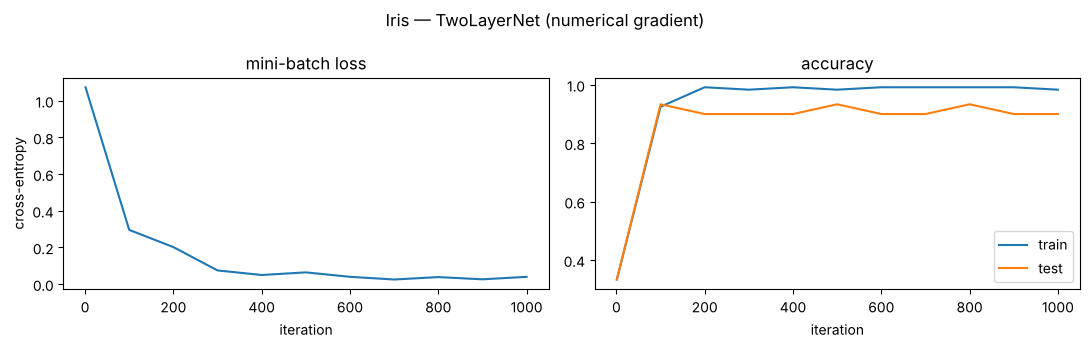

In [4]:
(x_train, t_train), (x_test, t_test) = load_iris_data(test_ratio=0.2, seed=0)
print("train:", x_train.shape, t_train.shape, " test:", x_test.shape, t_test.shape)

iris_net = TwoLayerNet(input_size=4, hidden_size=10, output_size=3)
iris_hist = train(iris_net, x_train, t_train, x_test, t_test,
                  iters=1000, batch_size=30, lr=0.5, log_every=100)
plot_history(iris_hist, "Iris — TwoLayerNet (numerical gradient)")

In [5]:
IRIS_MODEL = f"{LAST_NAME}_iris_nn_model.pkl"
save_model(iris_net, IRIS_MODEL)

saved -> almahaini_iris_nn_model.pkl


## 1.2 Test — load the saved model and evaluate every test sample

In [6]:
iris_loaded = load_model(IRIS_MODEL)
(_, _), (x_test, t_test) = load_iris_data(test_ratio=0.2, seed=0)

pred = np.argmax(iris_loaded.predict(x_test), axis=1)
actual = np.argmax(t_test, axis=1)

print(f"{'#':>3}  {'actual':<12}{'predicted':<12}result")
print("-" * 40)
for i, (a, p) in enumerate(zip(actual, pred)):
    print(f"{i:>3}  {IRIS_CLASSES[a]:<12}{IRIS_CLASSES[p]:<12}"
          f"{'correct' if a == p else 'INCORRECT'}")
print("-" * 40)
print(f"Iris test accuracy: {np.mean(pred == actual):.4f}  "
      f"({np.sum(pred == actual)}/{len(actual)} correct)")

  #  actual      predicted   result
----------------------------------------
  0  versicolor  versicolor  correct
  1  virginica   virginica   correct
  2  versicolor  versicolor  correct
  3  virginica   virginica   correct
  4  setosa      setosa      correct
  5  virginica   virginica   correct
  6  setosa      setosa      correct
  7  versicolor  versicolor  correct
  8  virginica   versicolor  INCORRECT
  9  virginica   virginica   correct
 10  virginica   virginica   correct
 11  versicolor  versicolor  correct
 12  setosa      setosa      correct
 13  setosa      setosa      correct
 14  versicolor  versicolor  correct
 15  versicolor  versicolor  correct
 16  setosa      setosa      correct
 17  versicolor  versicolor  correct
 18  setosa      setosa      correct
 19  versicolor  virginica   INCORRECT
 20  versicolor  versicolor  correct
 21  setosa      setosa      correct
 22  setosa      setosa      correct
 23  virginica   virginica   correct
 24  setosa      setosa      co

# Part 2 — MNIST

60 000 training / 10 000 test images, loaded directly from the IDX gzip files in
`dataset/`, flattened to 784 features and scaled to [0, 1].

> **Note on cost.** Numerical differentiation evaluates the full forward pass twice for
> *each* parameter. With a hidden layer of 20 units the network has
> 784·20 + 20 + 20·10 + 10 = **15 910** parameters, so one mini-batch update costs
> ~32 000 forward passes (~6 s). 300 iterations therefore take roughly 30 minutes —
> this is exactly why back-propagation (Chapter 5) exists.

## 2.1 Train

train: (60000, 784) (60000, 10)  test: (10000, 784) (10000, 10)


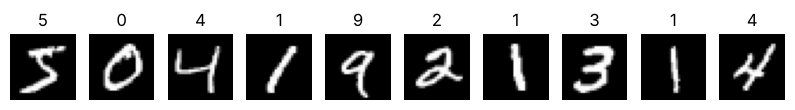

In [7]:
(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True, one_hot_label=True)
print("train:", x_train.shape, t_train.shape, " test:", x_test.shape, t_test.shape)

fig, ax = plt.subplots(1, 10, figsize=(10, 1.4))
for i in range(10):
    ax[i].imshow(x_train[i].reshape(28, 28), cmap="gray"); ax[i].axis("off")
    ax[i].set_title(int(np.argmax(t_train[i])))
plt.show()

iter     1 | loss 2.2443 | train acc 0.1124 | test acc 0.1135 |    8.3s


iter    25 | loss 2.1958 | train acc 0.3155 | test acc 0.3161 |  149.1s


iter    50 | loss 1.3669 | train acc 0.5725 | test acc 0.5800 |  297.5s


iter    75 | loss 0.9428 | train acc 0.7183 | test acc 0.7221 |  447.4s


iter   100 | loss 0.6671 | train acc 0.8258 | test acc 0.8298 |  597.3s


iter   125 | loss 0.4928 | train acc 0.8375 | test acc 0.8444 |  748.1s


... (3 outputs left out)

iter   225 | loss 0.2873 | train acc 0.8867 | test acc 0.8913 | 1347.4s


iter   250 | loss 0.3865 | train acc 0.8987 | test acc 0.8999 | 1494.4s


iter   275 | loss 0.3596 | train acc 0.8963 | test acc 0.8990 | 1640.2s


iter   300 | loss 0.2044 | train acc 0.9062 | test acc 0.9078 | 1786.9s


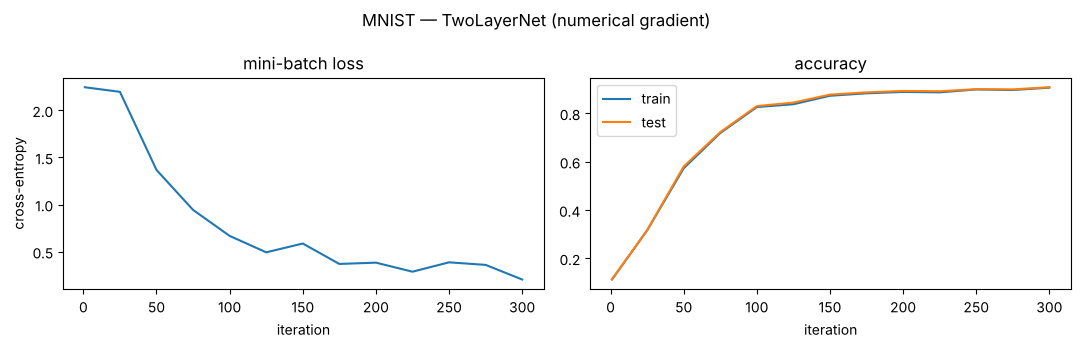

In [8]:
mnist_net = TwoLayerNet(input_size=784, hidden_size=20, output_size=10)
mnist_hist = train(mnist_net, x_train, t_train, x_test, t_test,
                   iters=300, batch_size=100, lr=1.0, log_every=25)
plot_history(mnist_hist, "MNIST — TwoLayerNet (numerical gradient)")

In [9]:
MNIST_MODEL = f"{LAST_NAME}_mnist_nn_model.pkl"
save_model(mnist_net, MNIST_MODEL)

saved -> almahaini_mnist_nn_model.pkl


## 2.2 Test — load the saved model and evaluate on the test set

In [10]:
mnist_loaded = load_model(MNIST_MODEL)
(_, _), (x_test, t_test) = load_mnist(normalize=True, one_hot_label=True)

pred = np.argmax(mnist_loaded.predict(x_test), axis=1)
actual = np.argmax(t_test, axis=1)
print(f"MNIST test accuracy: {np.mean(pred == actual):.4f}  "
      f"({np.sum(pred == actual)}/{len(actual)} correct)")

MNIST test accuracy: 0.9078  (9078/10000 correct)


In [11]:
# Actual vs. predicted for the first 20 test samples
print(f"{'#':>3}  {'actual':>6}  {'predicted':>9}  result")
print("-" * 36)
for i in range(20):
    print(f"{i:>3}  {actual[i]:>6}  {pred[i]:>9}  {'correct' if actual[i] == pred[i] else 'INCORRECT'}")

  #  actual  predicted  result
------------------------------------
  0       7          7  correct
  1       2          2  correct
  2       1          1  correct
  3       0          0  correct
  4       4          4  correct
  5       1          1  correct
  6       4          4  correct
  7       9          9  correct
  8       5          6  INCORRECT
  9       9          9  correct
 10       0          0  correct
 11       6          6  correct
 12       9          9  correct
 13       0          0  correct
 14       1          1  correct
 15       5          5  correct
 16       9          9  correct
 17       7          7  correct
 18       3          3  correct
 19       4          4  correct


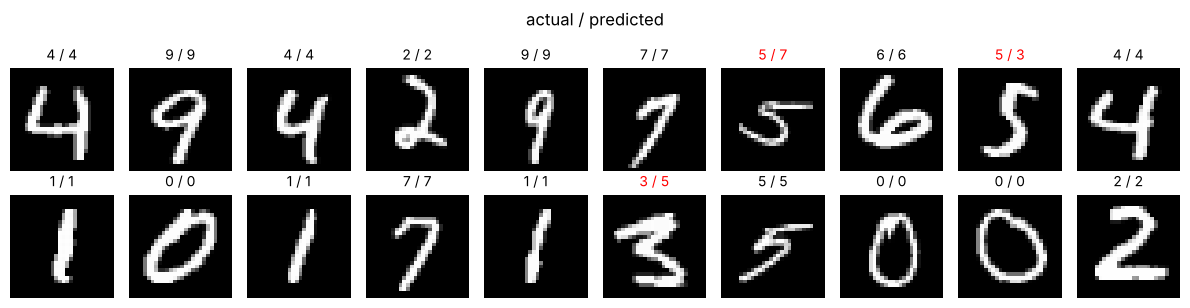

In [12]:
# Visual check: 20 random test digits, title = actual / predicted (red = wrong)
rng = np.random.default_rng(1)
sample = rng.choice(len(x_test), 20, replace=False)
fig, axes = plt.subplots(2, 10, figsize=(12, 3.2))
for ax, i in zip(axes.flat, sample):
    ax.imshow(x_test[i].reshape(28, 28), cmap="gray"); ax.axis("off")
    ok = actual[i] == pred[i]
    ax.set_title(f"{actual[i]} / {pred[i]}", color="black" if ok else "red", fontsize=10)
plt.suptitle("actual / predicted"); plt.tight_layout(); plt.show()

In [13]:
# Per-class accuracy and confusion matrix
cm = np.zeros((10, 10), dtype=int)
for a, p in zip(actual, pred):
    cm[a, p] += 1
print("per-class accuracy:")
for c in range(10):
    print(f"  digit {c}: {cm[c, c] / cm[c].sum():.4f}")
print("\nconfusion matrix (rows = actual, cols = predicted):")
print(cm)

per-class accuracy:
  digit 0: 0.9724
  digit 1: 0.9850
  digit 2: 0.9002
  digit 3: 0.8822
  digit 4: 0.9277
  digit 5: 0.8161
  digit 6: 0.9426
  digit 7: 0.9173
  digit 8: 0.8522
  digit 9: 0.8642

confusion matrix (rows = actual, cols = predicted):
[[ 953    0    4    1    0    7   10    4    1    0]
 [   0 1118    3    3    0    1    4    2    4    0]
 [  14    4  929    9   15    1   18   18   21    3]
 [   4    1   32  891    0   40    3   23   14    2]
 [   1    3    5    0  911    1   21    2    2   36]
 [  21    4    8   47    8  728   29   13   27    7]
 [  22    3    9    0   14    5  903    0    2    0]
 [   5   11   27    1    7    0    0  943    0   34]
 [   9   11   16   16   12   18   26   17  830   19]
 [  13    7    2    9   60   10    1   30    5  872]]


# Summary

| Dataset | Architecture | Iterations | Batch | LR | Test accuracy |
|---|---|---|---|---|---|
| Iris  | 4 → 10 → 3    | 1000 | 30  | 0.5 | see Part 1.2 |
| MNIST | 784 → 20 → 10 | 300  | 100 | 1.0 | see Part 2.2 |

Both networks are trained purely with numerical gradients. Iris converges to near-perfect
accuracy in seconds; MNIST reaches roughly 90 % — limited by how few updates are affordable
when each one costs tens of thousands of forward passes.